# JupyerLab notebook example for PFAS related simulations

## Module imports

In [14]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

In [24]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [38]:
file = Path(rf"configuration_PFAS.toml")
uc = rp.UnitCell.from_toml(file)

2023-06-26 14:51:43,817::radiopyo::INFO::Loading config from file: configuration_PFAS.toml
2023-06-26 14:51:43,828::radiopyo::INFO::Resolving include: C:\Users\rtonneau\DEV\PYTHON\radiopyo\radiopyo\data\basic_water_radiolysis.toml
2023-06-26 14:51:43,840::radiopyo::INFO::File is loaded
2023-06-26 14:51:43,841::radiopyo::INFO::Beam configuration detected in config file
2023-06-26 14:51:43,844::radiopyo::INFO::Beam ConstantBeam(dose_rate=1.6e+03, max_dose=2000000.0) is setup
2023-06-26 14:51:43,844::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-06-26 14:51:43,849::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-06-26 14:51:43,851::radiopyo::INFO::CONFIG::28 K-reactions added
2023-06-26 14:51:43,852::radiopyo::INFO::CONFIG::0 Enzymatic reactions added
2023-06-26 14:51:43,853::radiopyo::INFO::CONFIG::5 Radiolytic reactions added
2023-06-26 14:51:43,855::radiopyo::INFO::CONFIG::16 Dynamical Species added.
2023-06-26 14:51:43,855::radiopyo::INFO::CONFIG::3 Constant

**2) Run sim over the first pulse**

In [4]:
uc.beam

ConstantBeam(dose_rate=20000.0, timer=Timer(period=inf, on_time=inf, start_time=0.0), max_dose=2000000.0, nickname='', time_at_max_dose=100.0, dose_per_pulse=inf, peak_dose_rate=20000.0)

In [ ]:
res = uc.run([1e-9, 500], atol=1e-8, rtol=1e-5)

2023-06-26 14:51:56,321::radiopyo::INFO::Starting simulation with t_span: [1e-09, 500] (jacobian use: True)


**Convert final result to pandas DataFrame**

In [34]:
df = res.to_pandas()

## Results usage

### Plot

In [8]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3

#### Water-only Radiolytic produced species

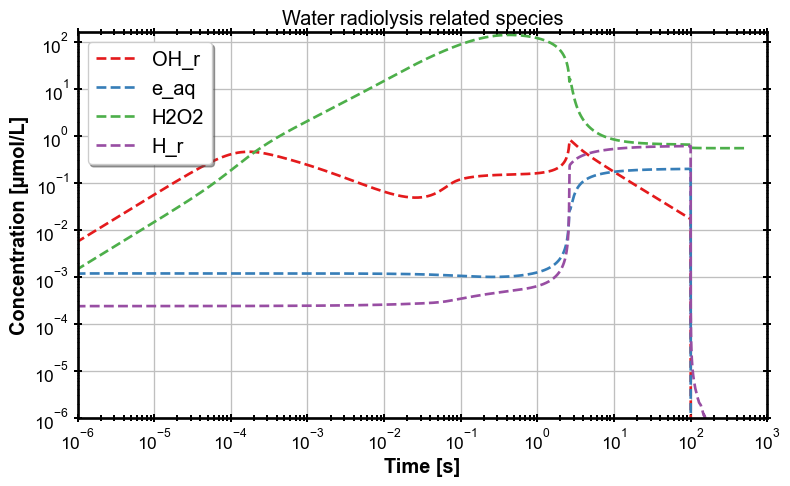

In [35]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
with fig_man.open(f"Radiolysis") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=1e-6)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Water radiolysis related species")


#### O2

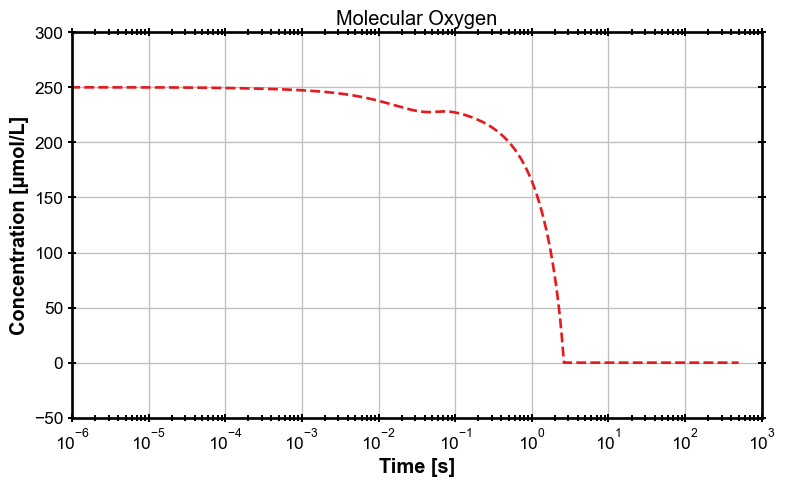

In [36]:
with fig_man.open(f"Molecular Oxygen") as (fig, ax):
    ax.plot(df.index, df["O2"], label=label, marker="")

    #ax.set_ylim(bottom=40, top=52)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.set_title("Molecular Oxygen")

#### PFAS species

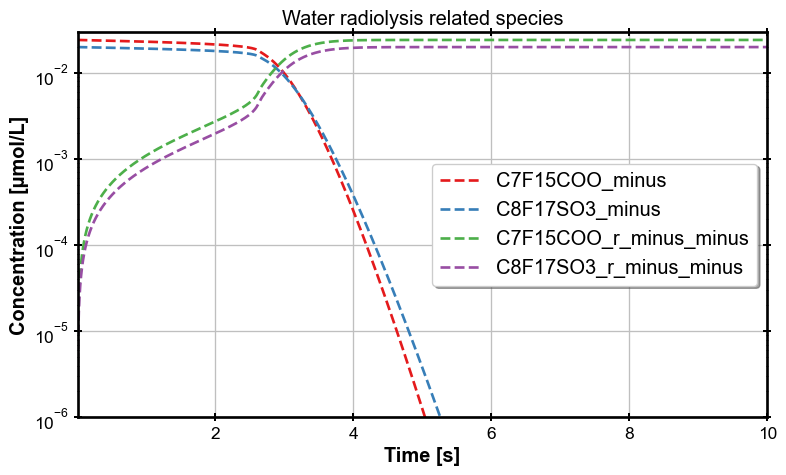

In [37]:
G_species = ["C7F15COO_minus", "C8F17SO3_minus", "C7F15COO_r_minus_minus", "C8F17SO3_r_minus_minus"]
with fig_man.open(f"PFAS Species") as (fig, ax):
    for label in G_species:
        ax.plot(df.index, df[label], label=label, marker="")

    ax.set_ylim(bottom=1e-6)
    ax.set_xlim([1e-6, 10])
    ax.set_xscale("linear")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Water radiolysis related species")
